### **Maestría en Inteligencia Artificial Aplicada**

###**Curso: Inteligencia Artificial y Aprendizaje Automático**

**Tecnológico de Monterrey**

Prof Luis Eduardo Falcón Morales

### **Actividad de la Semana: Problema de Clasificación con Datos Desbalanceados : Oil-Spill**

* **Nombre:** Luis Perez Rodriguez

* **Matrícula:** A01840795

# **Introducción**

* La actividad se basa en los datos conocidos como "oil-spill" (derrame de petróleo).

* En la web puedes encontrar varias referencias a este mismo problema, pero en donde el archivo de datos no es exactamente igual. Por ello y para asegurar que el conjunto de datos con el que estaremos trabajando es el mismo para todos, dicho archivo lo encontrarás en Canvas.

* El archivo con los datos de esta actividad lo encuentras en Canvas con el nombre "oil-spill.csv".

* En la siguiente liga se encuentra el artículo original relacionado a dicha base de datos:

https://webdocs.cs.ualberta.ca/~holte/Publications/oilspill.pdf

* De dicho artículo sabemos que los datos incluyen 50 columnas y 937 registros. Las primeras 49 columnas son métricas obtenidas de imágenes satelitales del océano, en algunas de las cuales se tiene petróleo que fue derramado por alguna fuente desconocida. En el artículo se describe a detalle la manera en que se obtuvieron dichas columnas. Para la presente actividad es suficiente con saber que dichos valores numéricos son información valiosa que nos permiten entender lo qu hay en la imagen, en particular, el ayudar a distinguir si hay o no derramamiento de combustible en dicha imagen.

* La última columna llamada "target" puede tomar el valor de 1 (hay derrame en ese pedazo de la imagen) o 0 (no hay derrame en ese pedazo de la imagen).

* Así, por el momento es suficiente con que consideres que cada una de las primeras 49 columnas son variables de tipo numérico continua y la última es de valor binario, en este problema de clasificación.

* En un curso posterior de visión computacional dentro de la maestría podrás estudiar técnicas para extraer dicha información numérica de las imágenes, en caso de que este tema sea de tu interés.

* Para fines de esta actividad usaremos la librería llamada "imbalanced-learn", usada comunmente en problemas de clases desbalanceadas. En particular, usaremos el siguiente método que nos proporciona un reporte con los valores de varias métricas utilizadas comunmente en problemas de clases desbalanceadas:

https://imbalanced-learn.org/stable/references/generated/imblearn.metrics.classification_report_imbalanced.html

In [52]:
# Incluye a continuación todas librerías que consideres necesarias:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_validate
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler, PowerTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import make_scorer
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
from sklearn.dummy import DummyClassifier
from imblearn.metrics import geometric_mean_score
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PowerTransformer, StandardScaler
from sklearn.model_selection import GridSearchCV, RepeatedStratifiedKFold
from sklearn.metrics import precision_recall_curve, auc
from imblearn.metrics import classification_report_imbalanced






**NOTAS:**

* **Para fines de esta actividad, pre-procesaremos los datos de manera genérica para poder concentrarnos en los temas relacionados al curso.**

* **Siempre podrás regresar en el futuro y trabajar de mejor manera el pre-procesamiento de los datos.**

In [23]:
# Cargamos los datos del archivo de la actividad:
path ='oil_spill.csv'
df = pd.read_csv(path)

# Eliminamos las siguientes columnas:
#   - f_1 contiene información de secciones (batches) de las imágenes que no requerimos para esta actividad.
#   - f_23 tiene un solo valor constante.
df.drop("f_1", axis=1, inplace=True)
df.drop("f_23", axis=1, inplace=True)

# Despleguemos los primeros valores:
print('Dimensión del DataFrame',df.shape)
df.head(4).T


Dimensión del DataFrame (937, 48)


,0,1,2,3
f_2,2558.00,22325.00,115.00,1201.00
f_3,1506.09,79.11,1449.85,1562.53
f_4,456.63,841.03,608.43,295.65
f_5,90.00,180.00,88.00,66.00
f_6,6395000.00,55812500.00,287500.00,3002500.00
f_7,40.88,51.11,40.42,42.40
f_8,7.89,1.21,7.34,7.97
f_9,29780.00,61900.00,3340.00,18030.00
f_10,0.19,0.02,0.18,0.19
f_11,214.70,901.70,86.10,166.50


In [24]:


# Particionamos los datos de entrada (X) y de salida (y):
X,y = df.iloc[:,:-1], df.iloc[:,-1]

# Utilizamos las semillas indicadas para la reproducibilidad de los resultados de la actividad:
Xtv, Xtest, ytv, ytest = train_test_split(X, y, test_size=0.12, stratify=y, shuffle=True, random_state=1)
Xtrain, Xval, ytrain, yval = train_test_split(Xtv, ytv, test_size=0.2, shuffle=True, random_state=7)


# Veamos que tenemos un problema de clases bastante desbalanceadas.
# Para ello mostremos la distribución de los conjuntos de entrenamiento, validación y prueba.
# En realidad, solo deberíamos mostrar los valores del conjunto de entrenamiento
# para evitar el problema del filtrado de información (data leakage). Sin embargo,
# con fines meramente euducativos, mostramos también la distribución de los conjuntos
# de validación (val) y de prueba (test), para darnos una idea de la complejidad del
# problema y del reto que tenemos para entrenar un buen modelo de clasificación.
# Es decir, tenemos una cantidad muy pequeña de datos de la clase positiva
# en el conjunto de validación y en el de prueba y aún así, deberemos
# hacer el esfuerzo para diseñar un buen modelo que distinga estos pocos datos.

print('\nPartición de los conjuntos de Entrenamiento, Validación y Prueba:')
print('+'*70)
tmp = 100 * (ytrain.sum() / len(ytrain))
print('Train:')
print('Conteo_clase_positiva= %d (%.2f%%)' % (ytrain.sum(), tmp))
print('Conteo_clase_negativa= %d (%.2f%%)' % ((len(ytrain)-ytrain.sum()), 100-tmp))

print('\nValidation:')
tmp = 100 * (yval.sum() / len(yval))
print('Conteo_clase_positiva= %d (%.2f%%)' % (yval.sum(), tmp))
print('Conteo_clase_negativa= %d (%.2f%%)' % ((len(yval)-yval.sum()), 100-tmp))

print('\nTest:')
tmp = 100 * (ytest.sum() / len(ytest))
print('Conteo_clase_positiva= %d (%.2f%%)' % (ytest.sum(), tmp))
print('Conteo_clase_negativa= %d (%.2f%%)' % ((len(ytest)-ytest.sum()), 100-tmp))


Partición de los conjuntos de Entrenamiento, Validación y Prueba:
++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
Train:
Conteo_clase_positiva= 28 (4.25%)
Conteo_clase_negativa= 631 (95.75%)

Validation:
Conteo_clase_positiva= 8 (4.85%)
Conteo_clase_negativa= 157 (95.15%)

Test:
Conteo_clase_positiva= 5 (4.42%)
Conteo_clase_negativa= 108 (95.58%)


# **Ejercicio-1**

### **Consideremos en primer instancia que los errores de falsos poitivos y falsos negativos son igualmente costosos. Y ya que tenemos un problema bastante desbalanceado, usaremos la media geométrica como métrica principal para buscar el mejor modelo. A partir de esta información, responde las siguientes preguntas:**

* ### **a) En el contexto de este problema del derrame de petróleo, ¿cómo justificas el no utilizar la métrica de la exactitud (accuracy), y sí utlizar la métrica G_mean?**

* ### **b) En el contexto del problema ¿qué significa un Falso Positivo y cuáles podrían ser algunas de sus implicaciones al cometer uno de estos errores?**

* ### **c) En el contexto del problema ¿qué significa un Falso Negativo y cuáles podrían ser algunas de sus implicaciones al cometer uno de estos errores?**





Respuestas Ejercicio-1:

### +++++++++++ Inicia sección para agregar texto ++++++++++++++++

* 1a) La exactitud (accuracy) mide la proporción total de predicciones correctas, pero puede resultar engañosa cuando las clases están muy desbalanceadas. En los conjuntos indicados, cerca del 95 % de los casos son negativos. Por ello, un modelo que clasificara todos los ejemplos como “sin derrame” podría alcanzar aproximadamente un 95 % de accuracy, aunque no detectara ningún derrame. La media geométrica o G-mean considera el desempeño en ambas clases:
$$
G\text{-mean}=\sqrt{\text{sensibilidad}\times\text{especificidad}}
$$ La sensibilidad mide qué proporción de los derrames detecta el modelo; la especificidad, qué proporción de los casos sin derrame clasifica correctamente. Si el modelo ignora una de las clases, una de esas medidas será baja y también lo será la G-mean. Por eso es más apropiada para comparar modelos en este problema desbalanceado, especialmente cuando los falsos positivos y falsos negativos se consideran igualmente costosos.

* 1b) Un falso positivo ocurre cuando el modelo indica que hay un derrame de petróleo, pero en realidad no lo hay. Esto podría provocar una inspección o respuesta de emergencia innecesaria: movilización de personal y equipos, análisis adicionales, interrupciones operativas o costos económicos. También puede generar falsas alarmas frecuentes y reducir la confianza en el sistema. Aunque se consideran igual de costosos que los falsos negativos para este análisis, sus consecuencias concretas dependen de cómo se use la predicción.

* 1c) Un falso negativo ocurre cuando existe un derrame, pero el modelo lo clasifica como ausencia de derrame. Este error puede retrasar la inspección y la contención, permitiendo que el petróleo se extienda y cause daños ambientales mayores. También puede elevar los costos de limpieza y recuperación, afectar a la fauna, los ecosistemas y las actividades económicas de la zona, además de generar consecuencias legales o ambientales. Por ello, es importante que el modelo no logre un buen resultado únicamente clasificando correctamente la clase mayoritaria, sino que también detecte los casos positivos.

### +++++++++++ Termina sección para agregar texto ++++++++++++++

* **Incluyamos a continuación una breve descripción numérica y gráfica del conjunto de entrenamiento. Es lo mínimo en cuanto a pre-procesamiento que haremos. Más adelante puedes regresar y realizar un mayor análisis.**

* **En dado caso, puedes incluir más celdas con análisis adicionales, si así lo deseas.**

In [25]:
Xtrain.describe().T

,count,mean,std,min,25%,50%,75%,max
f_2,659.0,350.377845,1.911459e+03,10.00,19.000,63.00,134.000,28526.00
f_3,659.0,692.040516,6.013521e+02,1.92,83.905,646.26,1229.325,1789.13
f_4,659.0,853.822398,5.259526e+02,1.00,435.500,719.81,1238.040,2724.57
f_5,659.0,85.613050,4.564260e+01,0.00,54.000,74.00,120.500,180.00
f_6,659.0,831366.966616,4.158159e+06,71718.00,125000.000,185000.00,337500.000,71315000.00
f_7,659.0,43.517132,1.287405e+01,21.24,33.760,40.35,53.090,82.64
f_8,659.0,9.244294,3.590490e+00,1.21,6.935,8.33,11.045,23.47
f_9,659.0,4094.624431,8.960913e+03,704.00,1332.000,2100.00,3445.000,160740.00
f_10,659.0,0.221730,8.687786e-02,0.02,0.170,0.21,0.260,0.67
f_11,659.0,110.794537,6.187135e+01,41.00,84.400,100.10,116.300,901.70


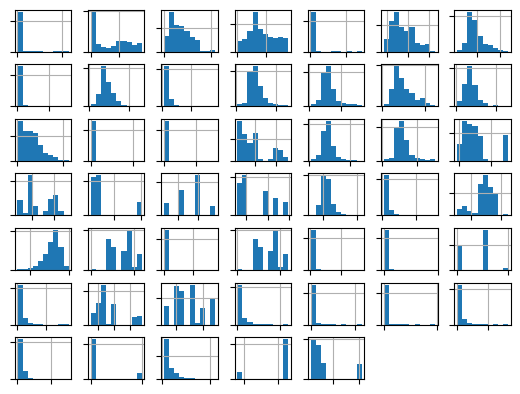

In [26]:
# Histogramas:
ax = Xtrain.hist()
# Quitemos toda la información del gráfico para visualizarlos de manera sencilla:
for axis in ax.flatten():
  axis.set_title('')
  axis.set_xticklabels([])
  axis.set_yticklabels([])
plt.show()



In [27]:
Xtrain.info()

<class 'pandas.core.frame.DataFrame'>
Index: 659 entries, 433 to 625
Data columns (total 47 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   f_2     659 non-null    int64  
 1   f_3     659 non-null    float64
 2   f_4     659 non-null    float64
 3   f_5     659 non-null    int64  
 4   f_6     659 non-null    float64
 5   f_7     659 non-null    float64
 6   f_8     659 non-null    float64
 7   f_9     659 non-null    float64
 8   f_10    659 non-null    float64
 9   f_11    659 non-null    float64
 10  f_12    659 non-null    float64
 11  f_13    659 non-null    float64
 12  f_14    659 non-null    float64
 13  f_15    659 non-null    float64
 14  f_16    659 non-null    float64
 15  f_17    659 non-null    float64
 16  f_18    659 non-null    float64
 17  f_19    659 non-null    float64
 18  f_20    659 non-null    float64
 19  f_21    659 non-null    float64
 20  f_22    659 non-null    float64
 21  f_24    659 non-null    float64
 22  f_25 

**En resumen:**

* De lo anterior observamos que:
  * Todos los valores ya son numéricos, positivos, negativos o cero.
  * No hay datos perdidios.
  * La diferencia de escala entre todos los factores es muy diversa y la distribución de las variables también es muy variada.

* **Como una primera aproximación transformaremos todos los factores con la Yeo-Johnson para corregir un poco el sesgo de las distribuciones que suele afectar en general a los modelos como la regresión logística y luego los escalaremos para ayudar a que todos los factores estén en iguales condiciones de mostrar su importancia.**

# **Ejercicio-2**

### **En relación a la transformación Yeo-Johnson, investiga:**

* ### **a) ¿En qué consiste dicha transformación?**

* ### **b) ¿Cuál es su diferencia con la transformación Box-Cox?**


Respuestas Ejercicio-2:

### +++++++++++ Inicia sección para agregar texto ++++++++++++++++

* 2a) La transformación Yeo-Johnson es una herramienta estadística fundamental en el preprocesamiento de datos para modelos de machine learning. Tiene una técnica de transformación de potencia diseñada para modificar la distribución de una variable numérica, buscando acercarla lo más posible a una distribución normal (gaussiana) y estabilizar su varianza. Al igual que otras transformaciones de potencia, utiliza un parámetro $\lambda$ (lambda) que se estima a partir de los datos para determinar la mejor función matemática (como logaritmos o potencias) que reduce la asimetría (skewness) de la distribución original

* 2b) La principal diferencia es el tipo de datos que pueden procesar, Box-Cox es la versión original, pero tiene una limitación estricta,
solo funciona con datos estrictamente positivos ($y > 0$), mientras que
Yeo-Johnson es una extensión de Box-Cox diseñada para ser más flexible. Puede aplicarse a datos que incluyen valores positivos, negativos y cero.



### +++++++++++ Termina sección para agregar texto ++++++++++++++

In [28]:
# Transformaciones numéricas evitando el filtrado de información:

numericas_pipeline = Pipeline(steps = [('impMediana', SimpleImputer(strategy='mean')),
                                       ('yeo-johnson', PowerTransformer(method='yeo-johnson')),
                                       ('std_transformer', StandardScaler()),
                                       ])

numericas_pipeline_nombres = Xtrain.columns

columnasTransformer = ColumnTransformer(transformers = [('num', numericas_pipeline, numericas_pipeline_nombres)],
                                        remainder='passthrough')

# **Ejercicio-3**

### **En este ejercicio deberás obtener el valor de umbral del modelo base (baseline) con el conjunto de entrenamiento, que nos ayude a determinar si un modelo está subentrenado.**

* ### **a) Encuentra la estrategia (strategy) del DummyClassifier más adecuada. Además, selecciona el número de divisiones (n_splits) de RepeatedStratifiedKFold que consideres sea el más adecuado para particionar en los conjuntos de entrenamiento y validación al aplicar validación cruzada con el modelo DummyClassifier. Prueba varios valores y observa el resultado de la media y desviación estándar antes de hacer tu mejor selección. Responde a continuación cómo llegaste a decidirte por valor que seleccionaste.**

* ### **b) Con base a tu mejor decisión para "strategy" y "n_splits", ¿cuál es el valor que se usará para determinar si un modelo está subentrenado, al usar la métrica G_mean?**

* ### **c) Si utilizáramos la métrica de la exactitud (accuracy) en este problema del derrame del petróleo, ¿cuál sería el valor de umbral del modelo base a superar? Incluye además la matriz de confusión de este modelo ingenuo con la métrica de la exactitud.**

Respuestas Ejercicio-3:

### +++++++++++ Inicia sección para agregar texto ++++++++++++++++


* 3a) Para este problema usaría strategy="stratified" y seleccionaría n_splits=5, con 10 repeticiones. La estrategia stratified asigna predicciones aleatorias respetando la proporción de clases observada en cada conjunto de entrenamiento. Así, el baseline intenta reconocer ambas clases y se puede evaluar con G-mean. En cambio, most_frequent siempre predice “sin derrame”; su sensibilidad es cero y, por tanto, su G-mean es cero. Puede servir como referencia trivial, pero no es un baseline informativo para comparar modelos que buscan detectar derrames. Con 28 casos positivos en el conjunto de entrenamiento, cinco divisiones dejan alrededor de 5 o 6 positivos en cada pliegue de validación. Al probar más divisiones, cada pliegue contiene menos positivos y la evaluación puede volverse más sensible a unos pocos aciertos o errores. Menos divisiones dan más positivos por pliegue, pero producen menos evaluaciones. Por eso, cinco es un equilibrio razonable; las repeticiones permiten observar la variabilidad entre particiones.



In [16]:


gmean_scorer = make_scorer(geometric_mean_score)

for n_splits in [3, 5, 7, 10]:
    cv = RepeatedStratifiedKFold(
        n_splits=n_splits,
        n_repeats=10,
        random_state=42
    )

    modelo = Pipeline([
        ("preprocesamiento", columnasTransformer),
        ("clasificador", DummyClassifier(
            strategy="stratified",
            random_state=42
        ))
    ])

    scores = cross_val_score(
        modelo, Xtrain, ytrain,
        cv=cv,
        scoring=gmean_scorer
    )

    print(
        f"n_splits={n_splits}: "
        f"media G-mean={scores.mean():.3f}, "
        f"desviación estándar={scores.std():.3f}"
    )

n_splits=3: media G-mean=0.065, desviación estándar=0.129
n_splits=5: media G-mean=0.075, desviación estándar=0.160
n_splits=7: media G-mean=0.063, desviación estándar=0.165
n_splits=10: media G-mean=0.075, desviación estándar=0.195


En el codigo se comparan la media y la desviación estándar de G-mean para cada valor. Con cinco divisiones se analiza un promedio razonable y una variabilidad no excesiva, considerando también que mantiene varios positivos en cada pliegue. No es posible reportar resultados numéricos sin ejecutar la validación sobre Xtrain y ytrain, la selección de cinco es una justificación metodológica basada en el número reducido de positivos. Como resultado tenemos un desempeño de referencia para comparar modelos, no un umbral de probabilidad de clasificación.

* 3b) El valor que se usará como referencia es la media de G-mean obtenida por el DummyClassifier con strategy="stratified" y n_splits=5 en la validación cruzada repetida. Un modelo cuyo G-mean de validación no supere de forma consistente esa referencia no demuestra una mejora sobre el baseline y podría estar subentrenado. No se puede dar un valor numérico sin ejecutar el código con Xtrain y ytrain; debe tomarse del resultado scores.mean(). Reporta también scores.std() para indicar la variabilidad de esa referencia.

* 3c) Con DummyClassifier(strategy="most_frequent"), el modelo base predice que todos los casos son negativos, porque esa clase representa la mayoría del conjunto. Por tanto, su accuracy es la proporción de negativos:
$$
\text{Accuracy}=\frac{631}{631+28}\approx 0.9575 = 95.75%
$$
Así, un modelo tendría que superar 95.75% de exactitud para vencer ese baseline en el conjunto de entrenamiento. Este umbral depende del conjunto evaluado: en validación sería 95.15% y en prueba, 95.58%, según los conteos proporcionados. La matriz de confusión del modelo ingenuo en entrenamiento, usando el orden de clases [negativa, positiva] para filas reales y columnas predichas, sería:

|                | Predicha: negativa | Predicha: positiva |
| -------------- | ------------------ | ------------------ |
| Real: negativa | 631                | 0                  |
| Real: positiva | 28                 | 0                  |

* Aunque la exactitud es alta, el modelo no detecta ningún derrame: su sensibilidad para la clase positiva es 0%.





### +++++++++++ Termina sección para agregar texto ++++++++++++++

NOTA: Recuerda revisar la documentación correspondiente de sklearn para la selección adecuada de los argumentos:

* DummyClassifier:

https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyClassifier.html

* RepeatedStratifiedKFold:

https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RepeatedStratifiedKFold.html

In [32]:
# Definamos una variable con la métrica G-mean a utilizar en los modelos:

mi_metrica = make_scorer(geometric_mean_score)


In [30]:
# Utilicemos la función DummyClassifier de sklearn con la métrica G-mean para
# obtener el desempeño del modelo base (baseline).

# Usa esta celda para probar diferentes valores de "strategy" y "n_splits".
# Con base a los resultados observados selecciona tus mejores opciones y
# responde a las preguntas de los incisos anteriores del Ejercicio-3.


# ----------------- Incluye a continuación tus mejores opciones -----------

mi_estrategia = 'stratified'

mi_nsplits = 5


# ----------------- Fin para realizar ajustes -----------------------------



# No modifiques las semillas.
cv = RepeatedStratifiedKFold(n_splits=mi_nsplits, n_repeats=3, random_state=7)  # Validación Cruzada Estratificada.
modeloD = DummyClassifier(strategy=mi_estrategia, random_state=7)
pipelineD = Pipeline(steps=[('ct',columnasTransformer),('Dummy',modeloD)])
scores = cross_val_score(pipelineD, Xtrain, ytrain, scoring=mi_metrica, cv=cv, n_jobs=-1)  # Cuidamos el filtrado de información.

print('Veamos los desempeños obtenidos con la DummyClassifier y la métrica G-mean.')
print('Imprimimos los resultados de todas las secciones (folds) generadas con Validación-Cruzada:')
print('+'*90)
print(scores)


print('\nObtenemos el valor promedio y desviación estandar (std) de dichos resultados:')
print('+'*80)
print('Promedio de los desempeños con la G-mean[Media Geométrica]=%.3f, std=(%.3f)' % (np.mean(scores), np.std(scores)))

Veamos los desempeños obtenidos con la DummyClassifier y la métrica G-mean.
Imprimimos los resultados de todas las secciones (folds) generadas con Validación-Cruzada:
++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
[0.         0.         0.         0.         0.         0.
 0.         0.40499526 0.         0.         0.         0.
 0.         0.40499526 0.        ]

Obtenemos el valor promedio y desviación estandar (std) de dichos resultados:
++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
Promedio de los desempeños con la G-mean[Media Geométrica]=0.054, std=(0.138)


# **Ejercicio-4**

* ### **Ya que tenemos las referencias de los modelos base (baseline) o ingenuo (naive) para las métricas de exactitud (accuracy) y G-mean. Ejecuta a continuación la siguiente celda. Observa que estaremos ejecutando los modelos con el mínimo de ajuste de los valores predeterminados de los hiperparámetros. Esto con el objetivo de tener un punto de partida sobre qué tan alejados estamos de obtener buenos modelos. Sirve también como ejemplo para mostrar cómo se  desempeñan los modelos cuando se ejecutan con sus valores predeterminados, que en muchas ocasiones son los resultados que muestran algunos LLM (modelos grandes de lenguaje). Esto nos muestra que no porque no tengamos errores de ejecución o compilación, no significa que ya alcanzamos el objetivo buscado.**

* ### **Observa que estamos usando los conjuntos Xtv y ytv para entrenar los modelos ya que estamos utilizando validación cruzada y además, mostramos al inicio que tenemos muy pocos datos de la clase positiva minoritaria en el conjunto de validación.**

Resultados de Validación:
LR
Exactitud: >> 0.947 (0.015)
G-mean: >> 0.654 (0.119)

LASSO
Exactitud: >> 0.960 (0.009)
G-mean: >> 0.501 (0.158)

RIDGE
Exactitud: >> 0.959 (0.008)
G-mean: >> 0.541 (0.113)

EN
Exactitud: >> 0.960 (0.007)
G-mean: >> 0.540 (0.109)

kNN
Exactitud: >> 0.956 (0.006)
G-mean: >> 0.174 (0.187)



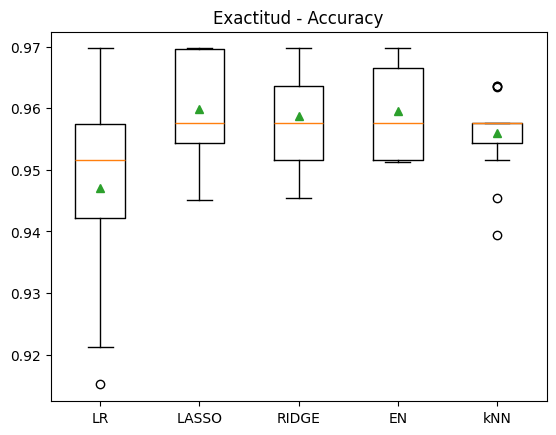

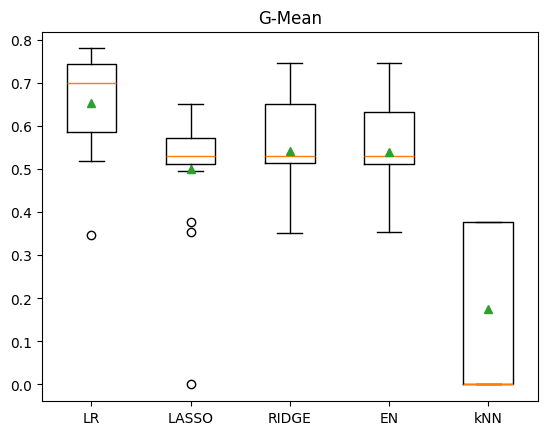

In [33]:
# Código-1:

# Ejecuta esta celda sin modificaciones.

# Estamos ejecutando los modelos con el mínimo de ajustes para usar sus valores predetermiandos
# y mostrando los desempeños con las métricas de exactitud (accuracy) y G-mean.


# Definimos primeramente los modelos a entrenar y evaluar:

def mis_modelos1():
  modelos, nombres = list(), list()

  modelos.append(LogisticRegression(penalty=None, # Este valor del argumento define el modelo sin regularización.
                                    max_iter=2000,
                                    random_state=1))
  nombres.append('LR')


  modelos.append(LogisticRegression(penalty='l1',  # modelo Lasso o de métrica L1.
                                    solver='liblinear',
                                    max_iter=2000,
                                    random_state=1))
  nombres.append('LASSO')


  modelos.append(LogisticRegression(penalty='l2',   # modelo Ridge o de métrica L2.
                                    max_iter=2000,
                                    random_state=1))
  nombres.append('RIDGE')

  modelos.append(LogisticRegression(penalty='elasticnet',  # modelo Elastic-Net o de métrica L1-L2.
                                    l1_ratio=0.5,
                                    solver='saga',
                                    max_iter=5000,
                                    random_state=1))
  nombres.append('EN')

  modelos.append(KNeighborsClassifier(n_neighbors=5))
  nombres.append('kNN')

  return modelos, nombres

# +++++++++++++++++++++++++++++++++++++++++++++++++++++++++


modelos, nombres = mis_modelos1()
resultados1, resultados2 = list(), list()
print('Resultados de Validación:')

for i in range(len(modelos)):

  pipeline = Pipeline(steps=[('ct',columnasTransformer),('m',modelos[i])])
  cv1 = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=7)
  scores = cross_validate(pipeline,
                          Xtv,
                          np.ravel(ytv),
                          scoring={'exactitud':'accuracy', 'm_geo':mi_metrica},
                          cv=cv1)

  resultados1.append(scores['test_exactitud'])
  resultados2.append(scores['test_m_geo'])

  print(nombres[i])
  print('Exactitud: >> %.3f (%.3f)' % (np.nanmean(scores['test_exactitud']), np.nanstd(scores['test_exactitud'])))
  print('G-mean: >> %.3f (%.3f)' % (np.nanmean(scores['test_m_geo']), np.nanstd(scores['test_m_geo'])))
  print()

plt.boxplot(resultados1, tick_labels=nombres,  showmeans=True)
plt.title("Exactitud - Accuracy")
plt.show()

plt.boxplot(resultados2, tick_labels=nombres,  showmeans=True)
plt.title("G-Mean")
plt.show()

### **Habiendo ejecutado la celda anterior sin ajustar hiperparámetros, responde lo siguiente:**

### **4a) ¿Cuáles modelos están subentrenados con respecto a la métrica de la exactitud (accuracy)?**

### **4b) ¿Cuáles modelos están subentrenados con respecto a la métrica de la media geométrica (G-mean)?**


### +++++++++++ Inicia sección para agregar texto ++++++++++++++++


* 4a) Tomando como referencia el baseline de exactitud del clasificador ingenuo (aproximadamente 0.958), los modelos con una exactitud media inferior a ese valor son: LR: 0.947
Ridge: 0.959? Wait user supplied 0.959 (above 0.958), LASSO .960 EN .960, kNN .956. Need nuance baseline likely accuracy 0.958? Train split 95.75. Ridge 0.959 narrowly exceeds. use precisely. LR y kNN están por debajo del baseline (LR 0.947; kNN 0.956), por lo que pueden considerarse subentrenados respecto a la exactitud. LASSO, Ridge y EN superan ligeramente la referencia, aunque esa diferencia es pequeña y no implica por sí sola que sean buenos modelos. La gráfica muestra además variabilidad entre folds; por eso, conviene interpretar la media junto con la desviación estándar. La exactitud, por sí sola, tampoco refleja bien la detección de la clase minoritaria.

* 4b) El baseline de G-mean de la DummyClassifier es 0.054. Comparando con esa referencia, ninguno de los modelos está subentrenado según la media geométrica, pues todos la superan: LR: 0.654 LASSO: 0.501 Ridge: 0.541 EN: 0.540 kNN: 0.174 Esto solo indica que superan el baseline; no necesariamente que su desempeño sea suficiente para la aplicación.


### +++++++++++ Termina sección para agregar texto ++++++++++++++

# **Ejercicio-6**

### **a) Selecciona el que consideres sea el mejor modelo encontrado, busca la mejor configuración de hiperparámetros y utilízalo para encontrar su matriz de confusión. Lamarlo "mejor_modelo". Sigue utilizando los mismos conjuntos de entrenamiento y validación. Llamar "ytrain_hat" y "yval_hat" a las predicciones de los conjuntos de entrenamiento y validación, respectivamente, obtenidas con el mejor modelo. Verifica ahora que tampoco quede sobreentrenado, considerando que la diferencia entre entrenamiento y validación no sea mayor al $3\%$. Utilizar random_state=1 en el modelo seleccionado.**

### **b) Observa que estamos también mostrando los valores de la exactitud de este mejor modelo. ¿Cómo justificas que el valor de la exactitud es menor que el obtenido anteriormente? Compara con la salida de la celda llamada "Código-1".**

###  **c) Con el mejor modelo y el conjunto de validación, obtener el gráfico de la curva-ROC, donde se incluya el valor del área bajo la curva AUC del mejor modelo y también el AUC del modelo que predice siempre la clase positiva (chance level). Ver documentación.**

###  **d) Con el mejor modelo y el conjunto de validación, obtener el gráfico de la curva-PR, donde se incluya el valor del área bajo la curva AUC del mejor modelo y también el AUC del modelo que siempre predice la clase positiva (chance level). Ver documentación.**

### **e) Con base a los resultados de los gráficos ROC y PR incluye tus conclusiones en el contexto del problema.**




In [46]:
# Respuesta Ejercicio-6a:

# **+++++++++++ Inicia sección para agregar código ++++++++++++++++**
# NOTA: puedes agregar todas las celdas que consideres adecuado.

gmean_scorer = make_scorer(geometric_mean_score)

# Preprocesamiento y modelo
pipeline = Pipeline([
    ("transformador", PowerTransformer(method="yeo-johnson")),
    ("escalador", StandardScaler()),
    ("modelo", LogisticRegression(random_state=1, max_iter=5000))
])

# Hiperparámetros a explorar
param_grid = {
    "modelo__C": [0.01, 0.1, 1, 10, 100],
    "modelo__class_weight": [None, "balanced"],
    "modelo__solver": ["lbfgs"],
}

# Validación cruzada estratificada
cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=10,
    random_state=1
)

busqueda = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring=gmean_scorer,
    cv=cv,
    n_jobs=-1,
    refit=True
)

# La búsqueda y el ajuste usan solo el conjunto de entrenamiento
busqueda.fit(Xtrain, np.ravel(ytrain))

# El mejor estimador queda ajustado con todo el conjunto de entrenamiento
mejor_modelo = busqueda.best_estimator_

print("Mejores hiperparámetros:", busqueda.best_params_)
print("G-mean promedio en validación cruzada: %.4f" % busqueda.best_score_)

# Predicciones solicitadas
ytrain_hat = mejor_modelo.predict(Xtrain)
yval_hat = mejor_modelo.predict(Xval)

# Métricas
gmean_train = geometric_mean_score(np.ravel(ytrain), ytrain_hat)
gmean_val = geometric_mean_score(np.ravel(yval), yval_hat)

# **+++++++++++ Termina sección para agregar código ++++++++++++++**

print('G-mean del mejor modelo-Train: %.4f' % geometric_mean_score(np.ravel(ytrain), ytrain_hat))
print('G-mean del mejor modelo-Val: %.4f' % geometric_mean_score(np.ravel(yval), yval_hat))

print('\nExactitud del mejor modelo-Train: %.4f' % accuracy_score(np.ravel(ytrain), ytrain_hat))
print('Exactitud del mejor modelo-Val: %.4f' % accuracy_score(np.ravel(yval), yval_hat))

print("\nMatriz de Confusión con Validación:\n", confusion_matrix(np.ravel(yval), yval_hat))

print("\nMatriz de Confusión en porcentajes y con Validación:\n", confusion_matrix(np.ravel(yval), yval_hat, normalize='all'))

Mejores hiperparámetros: {'modelo__C': 0.01, 'modelo__class_weight': 'balanced', 'modelo__solver': 'lbfgs'}
G-mean promedio en validación cruzada: 0.7352
G-mean del mejor modelo-Train: 0.8701
G-mean del mejor modelo-Val: 0.9273

Exactitud del mejor modelo-Train: 0.8498
Exactitud del mejor modelo-Val: 0.8667

Matriz de Confusión con Validación:
 [[135  22]
 [  0   8]]

Matriz de Confusión en porcentajes y con Validación:
 [[0.81818182 0.13333333]
 [0.         0.04848485]]


Respuesta Ejercicio-6b:

### +++++++++++ Inicia sección para agregar texto ++++++++++++++++
#### Comentario del gráfico curva PR:

* 6b)
La exactitud del mejor modelo puede ser menor que la reportada en Código-1 porque allí se comparaban modelos con sus hiperparámetros predeterminados, mientras que ahora la búsqueda selecciona la configuración que maximiza la G-mean, no la exactitud. Como las clases están muy desbalanceadas, maximizar la G-mean suele requerir detectar más casos positivos, aunque eso implique clasificar incorrectamente algunos negativos y reducir la exactitud global. La comparación debe hacerse sobre el mismo conjunto de evaluación. Si Código-1 reporta resultados de validación cruzada y el mejor modelo se evalúa en un conjunto de validación fijo, sus exactitudes no son directamente equivalentes: se calcularon sobre particiones distintas.


### +++++++++++ Termina sección para agregar texto ++++++++++++++

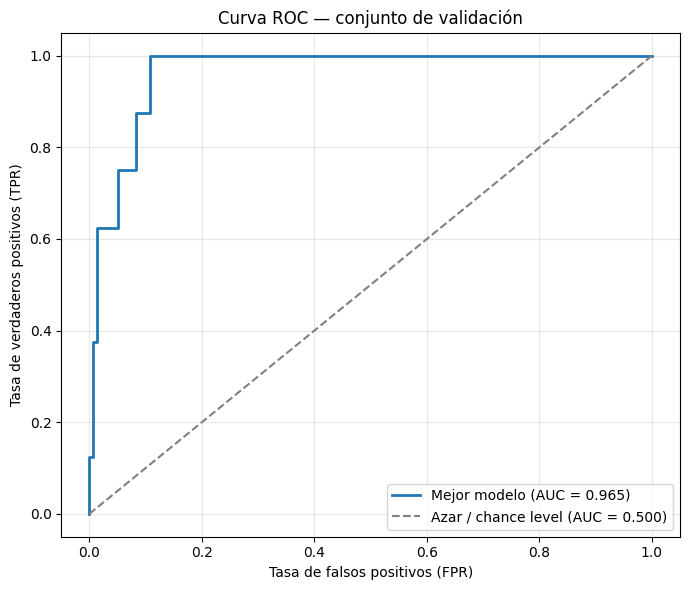

AUC del mejor modelo: 0.965
AUC de referencia (chance level): 0.500


In [47]:
# Respuesta Ejercicio-6c:

# **+++++++++++ Inicia sección para agregar código ++++++++++++++**

# Probabilidad estimada de la clase positiva (derrame)
yval_score = mejor_modelo.predict_proba(Xval)[:, 1]

# Curva ROC y AUC del mejor modelo
fpr, tpr, _ = roc_curve(yval, yval_score, pos_label=1)
auc_modelo = roc_auc_score(yval, yval_score)

# Curva ROC
plt.figure(figsize=(7, 6))
plt.plot(
    fpr, tpr,
    label=f"Mejor modelo (AUC = {auc_modelo:.3f})",
    linewidth=2
)

# Referencia de azar (AUC = 0.5)
plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Azar / chance level (AUC = 0.500)"
)

plt.xlabel("Tasa de falsos positivos (FPR)")
plt.ylabel("Tasa de verdaderos positivos (TPR)")
plt.title("Curva ROC — conjunto de validación")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"AUC del mejor modelo: {auc_modelo:.3f}")
print("AUC de referencia (chance level): 0.500")



# **+++++++++++ Termina sección para agregar código ++++++++++++++**

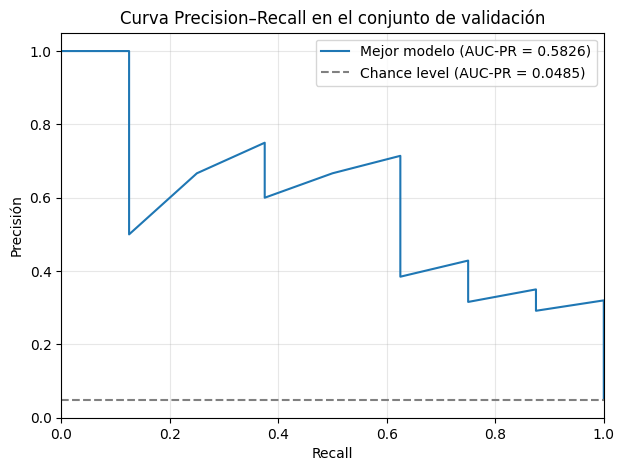

AUC-PR del mejor modelo: 0.5826
AUC-PR del chance level: 0.0485


In [49]:
# Respuesta Ejercicio 6d:

# **+++++++++++ Inicia sección para agregar código ++++++++++++++**

# Etiquetas reales y probabilidad estimada de la clase positiva
yval_real = np.ravel(yval)

# Ubicar la columna correspondiente a la clase positiva (etiqueta 1)
indice_positivo = list(mejor_modelo.classes_).index(1)
yval_scores = mejor_modelo.predict_proba(Xval)[:, indice_positivo]

# Curva PR y área bajo la curva del mejor modelo
precision, recall, _ = precision_recall_curve(yval_real, yval_scores)
auc_pr = auc(recall, precision)

# Chance level: clasificador que siempre predice la clase positiva
proporcion_positiva = np.mean(yval_real == 1)

# Gráfico
plt.figure(figsize=(7, 5))
plt.plot(recall, precision, label=f'Mejor modelo (AUC-PR = {auc_pr:.4f})')
plt.axhline(
    y=proporcion_positiva,
    color='gray',
    linestyle='--',
    label=f'Chance level (AUC-PR = {proporcion_positiva:.4f})'
)

plt.xlabel('Recall')
plt.ylabel('Precisión')
plt.title('Curva Precision–Recall en el conjunto de validación')
plt.xlim(0, 1)
plt.ylim(0, 1.05)
plt.legend(loc='best')
plt.grid(True, alpha=0.3)
plt.show()

print("AUC-PR del mejor modelo: %.4f" % auc_pr)
print("AUC-PR del chance level: %.4f" % proporcion_positiva)



# **+++++++++++ Termina sección para agregar código ++++++++++++++**

Respuesta Ejercicio-6e:

### +++++++++++ Inicia sección para agregar texto ++++++++++++++++

* 6e) En conjunto, los gráficos ROC y PR permiten valorar el desempeño del mejor modelo desde perspectivas complementarias. La curva ROC muestra el equilibrio entre la capacidad de detectar derrames (sensibilidad) y la capacidad de descartar falsas alarmas (especificidad).La curva PR se centra en la clase positiva y permite evaluar qué tan confiables son las alertas que genera el modelo, aspecto especialmente relevante porque los derrames son poco frecuentes en el conjunto de datos.
Si las curvas del modelo se mantienen por encima de sus respectivas referencias la diagonal en ROC y la prevalencia de casos positivos en PR, el modelo aporta capacidad predictiva frente a una clasificación aleatoria. Un AUC-PR claramente superior al chance level indicaría que el modelo identifica derrames con mayor precisión que una estrategia sin capacidad de discriminación, aun que una curva ROC favorable no basta por sí sola: con un fuerte desbalance, pueden existir muchas falsas alarmas o derrames no detectados, aunque el desempeño ROC parezca aceptable. Un umbral bajo puede aumentar la detección de derrames, pero también generar más falsas alarmas y movilizaciones innecesarias. Un umbral alto puede reducir esas falsas alarmas, pero dejar derrames sin detectar, con posibles consecuencias ambientales y económicas.Para tratar de mitigarlo,  el umbral de decisión debe elegirse considerando los costos reales de ambos errores y que se hayan considerado igualmente costosos en esta etapa es una hipótesis de trabajo, no necesariamente una condición del sistema real. Los resultados de validación deben interpretarse objetivamente, hay pocos casos positivos, de modo que una o dos predicciones pueden cambiar de manera apreciable las métricas y la forma de las curvas. La evaluación final debería realizarse una sola vez en el conjunto de prueba y, antes de una implementación, complementarse con más datos y una validación en condiciones operativas.


### +++++++++++ Termina sección para agregar texto ++++++++++++++

In [53]:
# Mostremos finalmente el siguiente resumen con varias métricas:

print(classification_report_imbalanced(np.ravel(yval), yval_hat,
                                       target_names=['class 0:non-spill', 'class 1:oil-spill']))

                         pre       rec       spe        f1       geo       iba       sup

class 0:non-spill       1.00      0.86      1.00      0.92      0.93      0.85       157
class 1:oil-spill       0.27      1.00      0.86      0.42      0.93      0.87         8

      avg / total       0.96      0.87      0.99      0.90      0.93      0.85       165



# **Ejercicio-7**

En los ejercicios previos ya lograste entrenar un buen modelo utilizando la métrica G-mean. Sin embargo, sabemos que en la industria un modelo no se despliega solamente porque tiene buenas métricas estadísticas, se despliega para resolver un problema de negocio. Introduzcamos a continuación información en esta dirección.

En los ejercicios anteriores el umbral de decisión por defecto del modelo logístico (independientemente de si usamos L1, L2 o ElasticNet) fue 0.5. Con este valor de decisión de 0.5 y del reporte de métricas de la celda anterior, observamos que aproximadamente el modelo detecta el 100% de los derrames (Recall ≈ 1.0), pero a costa de generar muchas falsas alarmas (Precisión ≈ 0.32).

Sabemos que el umbral de decisión predeterminado de 0.5 de los modelos logísticos es una convención arbitraria. Como ingenieros de IA, deberán ajustar ahora este umbral tomando en cuenta el costo de de cada nuno de los errores.

* **El Escenario de Negocio es el siguiente: Imagina que estás desplegando este modelo para la Guardia Costera y la Agencia de Protección Ambiental y te proporcionan la siguiente información:**

   * **Costo de un Falso Negativo (FN):** Cuando el modelo predice erróneamente que el "océano está limpio" y que no hay derrame de combustible, el costo es de $1,000,000 USD. El costo considera multas, limpieza de emergencia, daño ecológico, técnicos especialistas, disminución de tu reputación, etc.

   * **Costo de un Falso Positivo (FP):** Cuando el modelo predice erróneamente que "sí hay derrame", el costo es de $15,000 USD. Puede ser la detección de los llamados casos "look-alike", como las manchas de algas, entre otros. El costo considera el uso y combustible de un helicóptero para inspeccionar, horas hombre, entre otros.

   * El costo de error de los **casos Verdaderos (TP y TN)** es de $0 USD.

* **7a) Con base a esta información y tu mejor modelo encontrado previamente, utiliza un modelo de lenguaje de gran tamaño, LLM, para que te ayude a escribir una función en Python que calcule el "Costo Total Esperado" del problema, iterando a través de diferentes umbrales de probabilidad (desde 0.1 hasta 0.9). Utiliza solamente el conjunto de validación.**

* **7b) Incluye además una gráfica del Costo Total Esperado (eje Y)contre el valor de umbral (eje X). Despliega e indica visualmente dicho valor del umbral óptimo obtenido y su valor del costo total asociado.**

* **7c) A modo de comparación, muestra la matriz de confusión (en valores brutos) y el valor de la métrica G-mean para el caso del umbral de decisión predeterminado 0.5 y el del mejor umbral obtenido en los incisos anteriores.**

* **7d) ¿Cómo cambia la estrategia de despliegue respecto al umbral original predeterminado de 0.5? En particular, ¿consideras que vale la pena cambiarlo?**

* **7e) Indica el LLM utilizado e incluye el prompt o prompts que usaste en los incisos 7a y 7b anteriores.**





 Umbral  TN  FP  FN  TP  Costo total esperado (USD)
    0.1  20 137   0   8                     2055000
    0.2  64  93   0   8                     1395000
    0.3 109  48   0   8                      720000
    0.4 125  32   0   8                      480000
    0.5 135  22   0   8                      330000
    0.6 143  14   1   7                     1210000
    0.7 149   8   2   6                     2120000
    0.8 155   2   4   4                     4030000
    0.9 156   1   7   1                     7015000


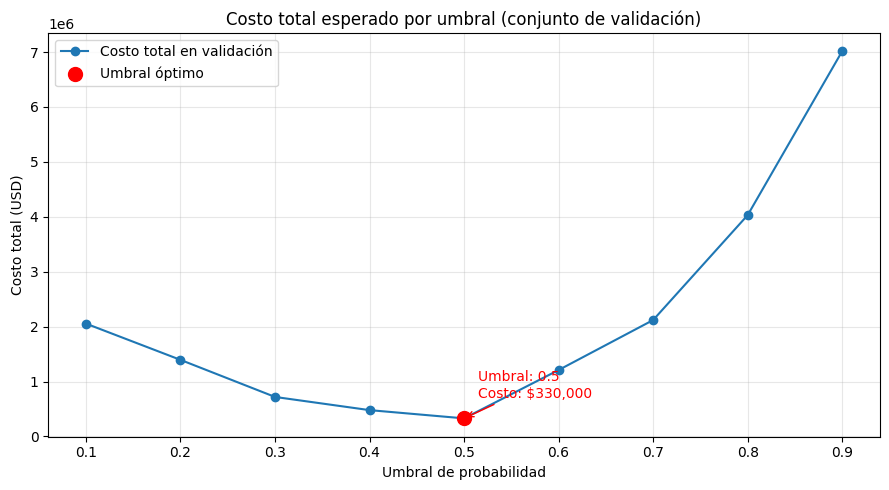

Umbral óptimo: 0.5
Costo total asociado: $330,000

Umbral predeterminado: 0.500
Matriz de confusión (filas: real; columnas: predicha):
[[135  22]
 [  0   8]]
G-mean: 0.927

Mejor umbral en validación: 0.500
Matriz de confusión (filas: real; columnas: predicha):
[[135  22]
 [  0   8]]
G-mean: 0.927


In [57]:
# Respuesta Ejercicio 7:

# +++++++ Incluye a continuación todos las celdas de texto y código que consideres adecuadas.
def calcular_costos_umbral(mejor_modelo, Xval, yval):
    costo_fn = 1_000_000  # Falso Negativo
    costo_fp = 15_000     # Falso Positivo

    # Probabilidad estimada de derrame (clase positiva)
    probabilidades = mejor_modelo.predict_proba(Xval)[:, 1]

    resultados = []

    for umbral in np.arange(0.1, 1.0, 0.1):
        predicciones = (probabilidades >= umbral).astype(int)
        tn, fp, fn, tp = confusion_matrix(
            yval, predicciones, labels=[0, 1]
        ).ravel()

        costo_total = (fn * costo_fn) + (fp * costo_fp)

        resultados.append({
            "Umbral": round(umbral, 1),
            "TN": tn,
            "FP": fp,
            "FN": fn,
            "TP": tp,
            "Costo total esperado (USD)": costo_total
        })

    return pd.DataFrame(resultados)

# Evaluación en el conjunto de validación
resultados_costos = calcular_costos_umbral(mejor_modelo, Xval, yval)
print(resultados_costos.to_string(index=False))
# 7b
def evaluar_y_graficar_costos(mejor_modelo, Xval, yval):
    costo_fn = 1_000_000
    costo_fp = 15_000
    umbrales = np.arange(0.1, 1.0, 0.1)

    probabilidades = mejor_modelo.predict_proba(Xval)[:, 1]
    resultados = []

    for umbral in umbrales:
        predicciones = (probabilidades >= umbral).astype(int)
        tn, fp, fn, tp = confusion_matrix(
            yval, predicciones, labels=[0, 1]
        ).ravel()

        costo_total = costo_fn * fn + costo_fp * fp
        resultados.append({
            "Umbral": umbral,
            "TN": tn, "FP": fp, "FN": fn, "TP": tp,
            "Costo total (USD)": costo_total
        })

    resultados = pd.DataFrame(resultados)
    indice_optimo = resultados["Costo total (USD)"].idxmin()
    optimo = resultados.loc[indice_optimo]

    plt.figure(figsize=(9, 5))
    plt.plot(
        resultados["Umbral"],
        resultados["Costo total (USD)"],
        marker="o",
        label="Costo total en validación"
    )
    plt.scatter(
        optimo["Umbral"],
        optimo["Costo total (USD)"],
        color="red",
        s=100,
        zorder=3,
        label="Umbral óptimo"
    )
    plt.annotate(
        f"Umbral: {optimo['Umbral']:.1f}\n"
        f"Costo: ${optimo['Costo total (USD)']:,.0f}",
        xy=(optimo["Umbral"], optimo["Costo total (USD)"]),
        xytext=(10, 15),
        textcoords="offset points",
        color="red",
        arrowprops={"arrowstyle": "->", "color": "red"}
    )

    plt.xlabel("Umbral de probabilidad")
    plt.ylabel("Costo total (USD)")
    plt.title("Costo total esperado por umbral (conjunto de validación)")
    plt.xticks(umbrales)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

    print(
        f"Umbral óptimo: {optimo['Umbral']:.1f}\n"
        f"Costo total asociado: ${optimo['Costo total (USD)']:,.0f}"
    )

    return resultados, optimo

resultados_costos, umbral_optimo = evaluar_y_graficar_costos(
    mejor_modelo, Xval, yval
)

# 7c
probabilidades = mejor_modelo.predict_proba(Xval)[:, 1]

# Sustituye esta variable por el umbral óptimo calculado en los incisos anteriores.
# Por ejemplo: umbral_optimo = 0.3
umbral_optimo = float(umbral_optimo["Umbral"])

for nombre, umbral in [
    ("Umbral predeterminado", 0.5),
    ("Mejor umbral en validación", umbral_optimo)
]:
    y_pred = (probabilidades >= umbral).astype(int)

    matriz = confusion_matrix(yval, y_pred, labels=[0, 1])
    gmean = geometric_mean_score(yval, y_pred, pos_label=1)

    print(f"\n{nombre}: {umbral:.3f}")
    print("Matriz de confusión (filas: real; columnas: predicha):")
    print(matriz)
    print(f"G-mean: {gmean:.3f}")

7c.-
Si el mejor umbral obtenido en validación es menor que 0.5, el sistema señalará más casos como posibles derrames. Eso suele aumentar la detección de derrames (menos falsos negativos), pero también puede generar más falsas alarmas (más falsos positivos). Si el umbral es mayor, ocurrirá lo contrario. Con los costos planteados —$1,000,000 por falso negativo frente a $15,000 por falso positivo—, un falso negativo cuesta aproximadamente 67 veces más que un falso positivo. Por eso, sí puede valer la pena cambiar el umbral de 0.5, siempre que el umbral alternativo reduzca el costo total esperado y que el aumento de falsas alarmas sea operativamente manejable. El cambio debe basarse en la comparación de la matriz de confusión y el costo de ambos umbrales en validación, no solo en el G-mean: el umbral que maximiza G-mean no necesariamente minimiza el costo. Como hay pocos derrames positivos, la estimación es incierta; conviene confirmar la decisión en datos representativos y revisar los costos reales antes del despliegue.

#7e)
OpenAI. (2026). ChatGPT (GPT-4) [Modelo de lenguaje grande]. https://chat.openai.com/
#7a
"escribeme una función en Python que calcule el "Costo Total Esperado" del problema, iterando a través de diferentes umbrales de probabilidad (desde 0.1 hasta 0.9). Utiliza solamente el conjunto de validación, considerando el siguiente escenario: El Escenario de Negocio es el siguiente: Imagina que estás desplegando este modelo para la Guardia Costera y la Agencia de Protección Ambiental y te proporcionan la siguiente información:

Costo de un Falso Negativo (FN): Cuando el modelo predice erróneamente que el "océano está limpio" y que no hay derrame de combustible, el costo es de $1,000,000 USD. El costo considera multas, limpieza de emergencia, daño ecológico, técnicos especialistas, disminución de tu reputación, etc.

Costo de un Falso Positivo (FP): Cuando el modelo predice erróneamente que "sí hay derrame", el costo es de $15,000 USD. Puede ser la detección de los llamados casos "look-alike", como las manchas de algas, entre otros. El costo considera el uso y combustible de un helicóptero para inspeccionar, horas hombre, entre otros.

El costo de error de los casos Verdaderos (TP y TN) es de $0 USD."

#7b
"tomando en cuenta el resultado anterior generame una gráfica del Costo Total Esperado (eje Y)contre el valor de umbral (eje X) y Despliega e indica visualmente dicho valor del umbral óptimo obtenido y su valor del costo total asociado."

# **Ejercicio-8**

**Has completado el ciclo de desarrollo y análisis del modelo de detección de derrames. Considera que tenemos el problema de derramamiento de combustible anterior y todo el análisis que has realizado hasta ahora. A continuación, deberás hacer un reporte para "vender tu solución". Para ello, considera el siguiente escenario:**

* **Supongamos que eres el ingeniero líder de IA de la Guarda Costera. A tu Director de Operaciones (que no conoce de tecnicismos de IA o Estadística) le hicieron llegar un reporte generado automáticamente por una herramienta de Inteligencia de Negocio (BI, por sus siglas en inglés). La conclusión de dicho reporte dice lo siguiente:**

     * **"El modelo tiene una Exactitud (Accuracy) del 96%. ¡Es casi perfecto! Propongo despedir a los 3 analistas humanos y dejar que el modelo envíe automáticamente los helicópteros de inspección cada vez que detecte algo".**


* **Tú sabes que esta conclusión es peligrosa e incorrecta tan solo por el alto desbalanceo de clases, pero además porque ya tienes los resultados analíticos anteriores de esta actividad que te pueden ayudar a soportar mejores decisiones y refutar la conlusión del reporte de la herramienta de BI.**

* **Redacta un reporte ejecutivo de máximo 1 página (400 palabras aproximadamente) dirigido al Director de Operaciones y con las siguientes características:**
   * **El reporte no debe estar lleno te fórmulas o métricas. En dado caso, si decides mencionar explícitamente por ejemplo "G-mean" o "curva ROC", deberás primero explicarlas.**
   
   * **El reporte debe incluir una explicación de las implicaciones de cometer errores de FP o FN con el modelo ingenuo, en comparación con los resultados de tu mejor modelo. La explicación debe ser nuevamente en el contexto del problema y sin tecnicismos.**

   * **Propón un plan de despliegue concreto del modelo que justifique y ayude a mantener a los 2 analistas humanos en sus puestos de trabajo. NOTA: Puedes revisar y aporate en el concepto conocido en inglés como "Human-in-the-loop" en IA.**







Respuesta Ejercicio-8):

### +++++++++++ Inicia sección para agregar texto ++++++++++++++++

Reporte ejecutivo: uso responsable del modelo para detectar derrames<br>
Para: Director de Operaciones<br>
De: Ingeniería de IA de la Guardia Costera<br>
Asunto: Despliegue del modelo de detección de derrames<br>

El reporte de Inteligencia de Negocio destaca una exactitud cercana al 96%, pero esa cifra no significa que el sistema sea casi perfecto. En este problema, los derrames son poco frecuentes: un sistema puede acertar muchas veces simplemente indicando que no hay derrame. El modelo ingenuo (que favorece la clase más común) puede alcanzar una exactitud alta y, aun así, no detectar ningún derrame. En la práctica, eso implica que el combustible podría seguir extendiéndose mientras no se envía una inspección.

Nuestro mejor modelo inicial, de regresión logística, obtuvo una media de G-mean(es una medida que combina qué tan bien un modelo detecta los derrames y qué tan bien reconoce las zonas sin derrame, dando importancia a ambas cosas)con un resultado de 0.654 en validación, frente a 0.054 del modelo ingenuo. La G-mean resume si el sistema logra tanto detectar derrames como descartar correctamente las zonas sin derrame; es más informativa aquí que la exactitud por sí sola. Aun así, el modelo no es infalible. Un falso negativo (FN) es un derrame no detectado, con posibles daños ambientales y costos de respuesta mucho mayores. Un falso positivo (FP) es una alerta en una zona sin derrame: consume tiempo y recursos de inspección. Con los costos considerados en el análisis, un FN es mucho más costoso que un FP. Por eso se evaluó un umbral de alerta distinto del 0.5 predeterminado para equilibrar mejor esos riesgos. Ese umbral debe validarse operativamente antes de adoptarse como definitivo.

Recomendación: <br> Despliegue con supervisión humana, no envío automático de helicópteros. Mantengamos a los dos analistas como parte esencial del proceso:

El modelo examina las observaciones y prioriza las zonas según el riesgo estimado.
Los analistas revisan las alertas, contrastan la información disponible y deciden si escalar cada caso a inspección aérea.
Las alertas dudosas o de alto riesgo reciben revisión prioritaria; las decisiones y resultados de campo se registran para evaluar y mejorar el sistema.<br>
Se inicia con un piloto supervisado. Antes de ampliar su uso, se revisan periódicamente los derrames detectados, los omitidos, las falsas alarmas y la carga de trabajo generada.
El modelo no toma decisiones autónomas ni reemplaza el criterio operacional, ante señales críticas o incertidumbre, prevalece el protocolo de seguridad y la validacion humana con criterio.
Así, la herramienta es una ayuda para los analistas y enfocar su atención para responder con mayor oportunidad, mientras ellos aportan contexto, verifican alertas y evitan que errores del sistema se conviertan directamente en decisiones costosas o peligrosas.


### +++++++++++ Termina sección para agregar texto ++++++++++++++

# **Ejercicio-9**

### **Incluye tus conclusiones finales.**


### +++++++++++ Inicia sección de Conclusiones ++++++++++++++++
El ejercicio me permitió comprender que una métrica alta de exactitud no basta para afirmar que un modelo es adecuado, especialmente cuando los derrames son poco frecuentes. Un modelo puede acertar en la mayoría de los casos y, aun así, no detectar los derrames reales.

Al comparar los modelos, la regresión logística obtuvo el mejor G-mean promedio entre los modelos evaluados inicialmente y superó claramente el baseline ingenuo. Esto muestra que podía reconocer mejor ambas clases, aunque sus resultados todavía variaban entre particiones y no garantizan un buen desempeño en condiciones reales.

También entendí que la selección del modelo y del umbral de decisión depende de las consecuencias de cada error. En este problema, no detectar un derrame puede ser mucho más costoso que generar una falsa alarma, entonces conviene evaluar métricas como G-mean, sensibilidad y precisión, además de estimar los costos operativos, en lugar de optimizar únicamente la exactitud.

Creo que el modelo debe tratarse como una herramienta de apoyo y no como un sustituto del criterio humano. Antes de implementarlo, es necesario validar el umbral y el desempeño con datos de prueba que no se hayan usado durante el desarrollo, y realizar un piloto supervisado por analistas. Esto ayudaría a comprobar si las mejoras observadas en los datos se mantienen en la operación y a reducir el riesgo de tomar decisiones basadas en resultados inciertos.

En un trabajo real de detección de derrames, este ejercicio se reflejaría en un sistema que ayuda a los analistas a priorizar las zonas que conviene revisar primero, en lugar de depender únicamente de reportes manuales o de una alerta automática sin supervisión.

Sus principales ventajas serían:

Respuesta más rápida: el equipo podría enfocar primero los recursos en las zonas con mayor probabilidad de derrame.
Mejor uso de recursos: se reducirían inspecciones innecesarias y se aprovecharían mejor el tiempo de los analistas y los vuelos de vigilancia.
Menor riesgo de pasar por alto un derrame: al considerar el costo alto de los falsos negativos, el umbral de alerta puede ajustarse para favorecer la detección, siempre que el volumen de falsas alarmas sea manejable.
Decisiones más informadas: los analistas recibirían una estimación de riesgo que podrían combinar con imágenes, reportes y conocimiento del área.
Mejora continua: al registrar qué alertas fueron correctas y cuáles no, se podrían evaluar y actualizar el modelo.
En la práctica, el modelo sería un apoyo para priorizar y revisar alertas, no un reemplazo del personal ni una decisión automática de enviar recursos. Su utilidad tendría que confirmarse mediante un piloto supervisado y midiendo tanto los derrames detectados como las falsas alarmas.

### +++++++++++ Termina sección de conclusiones ++++++++++++++

# **<<< Fin de la Actividad de la Semana - Clases Desbalanceadas - Oil-Spill >>>**